In [ ]:
!pip install -qq diffusers datasets accelerate peft

# Colab trae preinstalada una version antigua de torchao que es incompatible con peft.
# peft solo la usa para cuantizacion (no la necesitamos), asi que la desinstalamos:
!pip uninstall -qq -y torchao

In [ ]:
# Importamos las librerias necesarias:
from diffusers import StableDiffusionPipeline, DDPMScheduler
from diffusers import UNet2DConditionModel, AutoencoderKL, LMSDiscreteScheduler
from diffusers.utils import convert_state_dict_to_diffusers
from transformers import CLIPTextModel, CLIPTokenizer
from datasets import load_dataset
from accelerate import Accelerator
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os
from tqdm import tqdm

In [ ]:
# Vamos a utilizar GPU, necesaria para el entrenamiento:

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


# Cargamos modelo pre entrenado

In [ ]:
pretrained_model_name = "CompVis/stable-diffusion-v1-4"

# Cargamos un modelo pre-entrenado Stable Diffusion:
pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
).to(device)

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

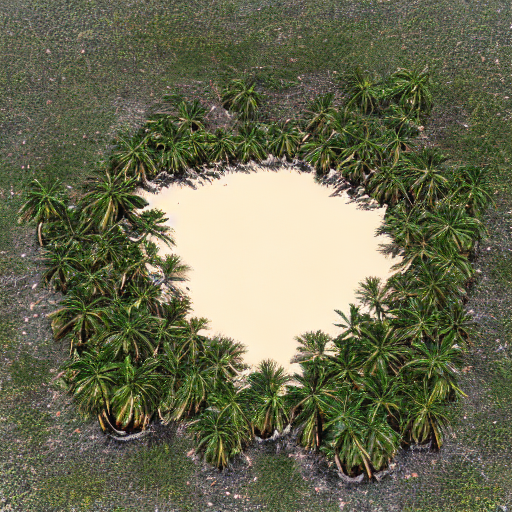

In [ ]:
# generamos imagen para probar dataset:

prompt = "an image of a desert island"

image = pipe(prompt).images[0]

image

# Cargamos dataset para finetunear

In [ ]:
dataset_name = "gigant/oldbookillustrations"

dataset = load_dataset(dataset_name, split="train")

# Comprobamos el tamaño del dataset y de sus imagenes:
dataset_size = len(dataset)
size = dataset[0]["1600px"].size
print(f"Dataset con {dataset_size} imagenes, de tamaño {size} cada una")

README.md:   0%|          | 0.00/8.54k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/4.03k [00:00<?, ?B/s]

data/train-00000-of-00013-c0326990f575de(…): reconstructing file:   0%|          |  0.00B /  628MB            

data/train-00000-of-00013-c0326990f575de(…): downloading bytes:           |  0.00B            

data/train-00001-of-00013-a511e1086f1718(…): reconstructing file:   0%|          |  0.00B /  439MB            

data/train-00001-of-00013-a511e1086f1718(…): downloading bytes:           |  0.00B            

... (20 outputs left out)

data/train-00012-of-00013-cf490ec155e3b8(…): reconstructing file:   0%|          |  0.00B /  388MB            

data/train-00012-of-00013-cf490ec155e3b8(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/4154 [00:00<?, ? examples/s]

Dataset con 4154 imagenes, de tamaño (1158, 1600) cada una


In [ ]:
# Seleccionamos únicamente las columnas que nos interesan

columnas_a_mantener = ["1600px", "info_alt"]
columnas_a_eliminar = [col for col in dataset.column_names if col not in columnas_a_mantener]

dataset_filtrado = dataset.remove_columns(columnas_a_eliminar)

print("Columnas restantes en el dataset:", dataset_filtrado.column_names)
display(dataset_filtrado[0])

Columnas restantes en el dataset: ['1600px', 'info_alt']


{'1600px': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1158x1600>,
 'info_alt': 'A bald man with a long beard smiles faintly as he carries on his back a little girl wearing his hat'}

In [ ]:
# Definimos las transformaciones necesarias para el dataset:
# pasamos Resize(resolution) con un entero en lugar de la tupla, así escala el lado corto a 512 y mantiene las proporciones. Después, CenterCrop recorta el centro a 512x512

resolution = 512
image_transforms = transforms.Compose([
    transforms.Resize(resolution),                           # lado corto a 512, sin deformar
    transforms.CenterCrop(resolution),                       # recorte central 512x512
    transforms.ToTensor(),                                   # convertir a tensor
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),  # normalizacion
])

Imagen transformada:


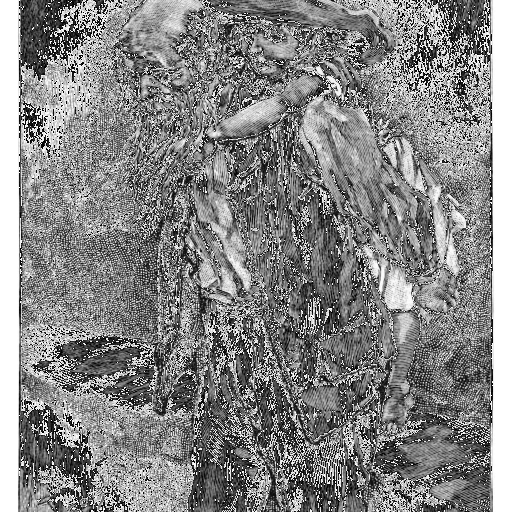

In [ ]:
# Aplicamos la transformacion a una imagen del dataset:
original_image = dataset[0]["1600px"]
transformed_image = image_transforms(original_image)
transformed_pil_image = transforms.ToPILImage()(transformed_image)

print("Imagen transformada:")
transformed_pil_image

In [ ]:
# Creamos un Dataset wrapper para la hora del entrenamiento:
batch_size = 3  # no puede ser mayor por la limitacion de GPU

# Para reducir los pasos por época, podemos seleccionar un subconjunto más pequeño del dataset:
limite_imagenes = 600
dataset_reducido = dataset.select(range(min(limite_imagenes, len(dataset))))

class Text2ImageDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        example = self.dataset[idx]
        image = image_transforms(example["1600px"].convert("RGB"))
        token = tokenizer(example["info_alt"], padding="max_length", truncation=True, max_length=tokenizer.model_max_length, return_tensors="pt")
        return {
            "pixel_values": image,
            "input_ids": token.input_ids.squeeze(0),
            "attention_mask": token.attention_mask.squeeze(0),
        }

train_dataset = Text2ImageDataset(dataset_reducido)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# 3. Cargamos las componentes del modelo por separado

In [ ]:
# Antes de cargar todas las componentes en GPU, la vaciamos:
del pipe
torch.cuda.empty_cache()

In [ ]:
# Tokenizador:
tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder='tokenizer')

# Scheduler:
noise_scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")

# Text Encoder (CLIP):
text_encoder = CLIPTextModel.from_pretrained(
    pretrained_model_name,
    subfolder="text_encoder",
).to(device)

# VAE: Autoencoder:
vae = AutoencoderKL.from_pretrained(
    pretrained_model_name,
    subfolder="vae",
).to(device)

# La UNet:
unet = UNet2DConditionModel.from_pretrained(
    pretrained_model_name,
    subfolder="unet",
).to(device)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [ ]:
# Congelamos los pesos del VAE y del Text Encoder, no se entrenan.
# La UNet original tambien quedara congelada: al añadir la LoRA (siguiente seccion), peft pone
# requires_grad=False en los pesos originales y solo deja entrenables las matrices de la LoRA.
vae.eval()
text_encoder.eval()

for param in vae.parameters():
    param.requires_grad = False
for param in text_encoder.parameters():
    param.requires_grad = False

# 4. Añadimos la LoRA y preparamos el entrenamiento

In [ ]:
# Hiperparametros de la LoRA:
lora_rank = 6     # rango de las matrices de bajo rango (4-16 suele ser suficiente)
lora_alpha = 6    # factor de escala de la LoRA (suele igualarse al rango)

# Inyectamos la LoRA en las capas de atencion de la UNet. peft congela los pesos base y crea
# las matrices de bajo rango entrenables:
lora_config = LoraConfig(
    r=lora_rank,
    lora_alpha=lora_alpha,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],
)
unet.add_adapter(lora_config, adapter_name="pokemon")

# Comprobamos cuantos parametros entrenamos realmente (solo la LoRA):
lora_params = [p for p in unet.parameters() if p.requires_grad]
n_lora = sum(p.numel() for p in lora_params)
n_total = sum(p.numel() for p in unet.parameters())
print(f"Parametros entrenables (LoRA): {n_lora:,} de {n_total:,} ({100 * n_lora / n_total:.2f}%)")

# Optimizador SOLO sobre los parametros de la LoRA:
learning_rate = 1e-4
optimizer = torch.optim.AdamW(lora_params, lr=learning_rate)

# Acelerador:
accelerator = Accelerator()
unet, optimizer, train_dataloader = accelerator.prepare(unet, optimizer, train_dataloader)
print(accelerator.device)

Parametros entrenables (LoRA): 1,195,776 de 860,716,740 (0.14%)
cuda


# Proceso de entrenamiento: finetuning con LoRA

In [ ]:
# Training loop:
num_epochs = 6

unet.train()
for epoch in range(num_epochs):
    progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch}")

    for batch in progress_bar:

        # Se pasan los pixeles al espacio latente con el encoder del VAE:
        with torch.no_grad():
            latents = vae.encode(batch["pixel_values"].to(accelerator.device)).latent_dist.sample()
            latents = latents * 0.18215

        # Proceso de difusion hacia delante:
        # 1. Creamos ruido aleatorio
        noise = torch.randn_like(latents)
        # 2. Cogemos un timestep aleatorio:
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (latents.shape[0],), device=latents.device).long()
        # 3. Añadimos ruido al vector del espacio latente:
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        # Codificamos el texto:
        encoder_hidden_states = text_encoder(batch["input_ids"].to(accelerator.device))[0]

        # Con el vector con ruido, el timestep, y el vector de texto, hacemos la prediccion de ruido:
        noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

        # Calculamos el error y actualizamos los parametros (solo los de la LoRA):
        loss = torch.nn.functional.mse_loss(noise_pred, noise)
        accelerator.backward(loss)
        optimizer.step()
        optimizer.zero_grad()

        progress_bar.set_postfix(loss=loss.item())

Epoch 5: 100%|██████████| 200/200 [14:10<00:00,  4.25s/it, loss=0.309]


#  Generamos imágenes con la LoRA entrenada:

In [ ]:
# Recuperamos la UNet entrenada (con la LoRA dentro) y la ponemos en modo evaluacion:
unet = accelerator.unwrap_model(unet)
unet.eval()

# Montamos el pipeline reutilizando las componentes que ya tenemos en GPU:
pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
    unet=unet,
    vae=vae,
    text_encoder=text_encoder,
    tokenizer=tokenizer,
).to(device)

print('Pipeline con LoRA listo!')

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Pipeline con LoRA listo!


  0%|          | 0/50 [00:00<?, ?it/s]

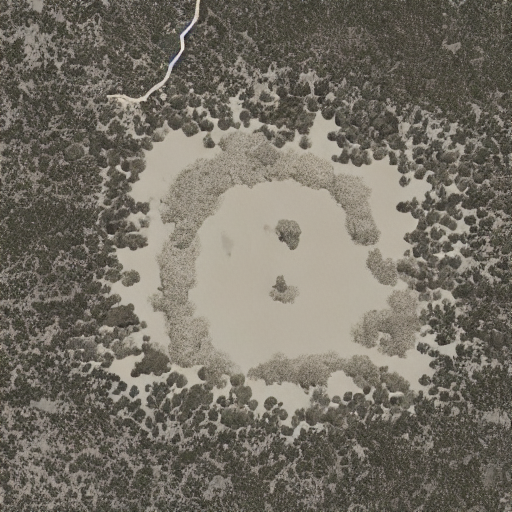

In [ ]:
# Generamos imágenes como las ilustraciones de los libros con el modelo base + LoRA:
prompt = "an image of a desert island"

image = pipe(prompt).images[0]

image

In [ ]:
from huggingface_hub import notebook_login
notebook_login()

# Iniciar sesión y definir variables

In [ ]:
from huggingface_hub import HfApi

output_dir = "sd-lora-oldbookillustrations"

unet_lora_state_dict = convert_state_dict_to_diffusers(
    get_peft_model_state_dict(unet, adapter_name="pokemon")
)
StableDiffusionPipeline.save_lora_weights(
    save_directory=output_dir,
    unet_lora_layers=unet_lora_state_dict,
    safe_serialization=True,
)

image.save(f"{output_dir}/ejemplo.png")

# Crear página del modelo

In [ ]:
readme = f"""---
base_model: {pretrained_model_name}
license: creativeml-openrail-m
library_name: diffusers
datasets:
- gigant/oldbookillustrations
tags:
- stable-diffusion
- text-to-image
- lora
- diffusers
---

# LoRA de ilustraciones de libros antiguos para Stable Diffusion v1.4

Ajuste fino con LoRA de `{pretrained_model_name}` sobre {limite_imagenes} imágenes de `gigant/oldbookillustrations`.

- Rango LoRA: {lora_rank}, alpha: {lora_alpha}
- Épocas: {num_epochs}, batch size: {batch_size}, learning rate: {learning_rate}
- Resolución: {resolution}x{resolution}
- Capas entrenadas: to_q, to_k, to_v, to_out.0 de la UNet

![ejemplo](ejemplo.png)

## Uso
```python
from diffusers import StableDiffusionPipeline
import torch
pipe = StableDiffusionPipeline.from_pretrained("{pretrained_model_name}", torch_dtype=torch.float16).to("cuda")
pipe.load_lora_weights("alvaroborre/sd-lora-oldbookillustrations")
pipe("an image of a desert island").images[0]
```
"""
with open(f"{output_dir}/README.md", "w") as f:
    f.write(readme)

In [ ]:
repo_id = "alvaroborre/sd-lora-oldbookillustrations"

api = HfApi()
api.create_repo(repo_id, exist_ok=True)
api.upload_folder(folder_path=output_dir, repo_id=repo_id)
print(f"https://huggingface.co/{repo_id}")

https://huggingface.co/alvaroborre/sd-lora-oldbookillustrations


In [ ]:
from huggingface_hub import notebook_login, HfApi
notebook_login()
api = HfApi()

pretrained_model_name = "CompVis/stable-diffusion-v1-4"
repo_lora = "alvaroborre/sd-lora-oldbookillustrations"

# Hiperparámetros usados en el entrenamiento (para el README):
limite_imagenes = 600
num_epochs = 6
batch_size = 3
lora_rank = 6
lora_alpha = 6
learning_rate = 1e-4
resolution = 512

# Fusionar la LoRA con el modelo base, y varga desde HuggimgFace

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

pytorch_lora_weights.safetensors: reconstructing file:   0%|          |  0.00B / 4.82MB            

pytorch_lora_weights.safetensors: downloading bytes:           |  0.00B            

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


  0%|          | 0/50 [00:00<?, ?it/s]

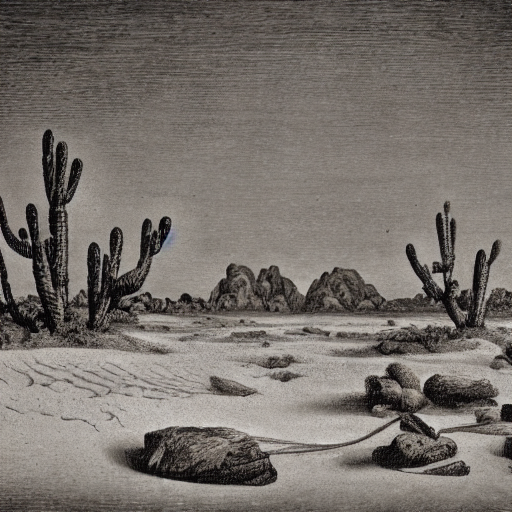

In [ ]:
pipe_full = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name, torch_dtype=torch.float16
).to(device)
pipe_full.load_lora_weights(repo_lora)

pipe_full.fuse_lora()
pipe_full.unload_lora_weights()

image_full = pipe_full("an image of a desert island").images[0]
image_full

# Guardar modelo completo y su README

In [ ]:
full_dir = "sd-oldbookillustrations"
pipe_full.save_pretrained(full_dir, safe_serialization=True)
image_full.save(f"{full_dir}/ejemplo.png")

readme_full = f"""---
base_model: {pretrained_model_name}
license: creativeml-openrail-m
library_name: diffusers
datasets:
- gigant/oldbookillustrations
tags:
- stable-diffusion
- text-to-image
- diffusers
---

# Stable Diffusion v1.4: ilustraciones de libros antiguos

Modelo completo: `{pretrained_model_name}` con la LoRA
[alvaroborre/sd-lora-oldbookillustrations](https://huggingface.co/alvaroborre/sd-lora-oldbookillustrations)
fusionada en la UNet.

Entrenamiento: {limite_imagenes} imágenes de `gigant/oldbookillustrations`, {num_epochs} épocas,
LoRA rango {lora_rank} / alpha {lora_alpha}, learning rate {learning_rate}, {resolution}x{resolution}.

![ejemplo](ejemplo.png)

## Uso
```python
from diffusers import StableDiffusionPipeline
import torch
pipe = StableDiffusionPipeline.from_pretrained("alvaroborre/sd-oldbookillustrations", torch_dtype=torch.float16).to("cuda")
pipe("an image of a desert island").images[0]
```
"""
with open(f"{full_dir}/README.md", "w") as f:
    f.write(readme_full)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
repo_full = "alvaroborre/sd-oldbookillustrations"
api.create_repo(repo_full, exist_ok=True)
api.upload_folder(folder_path=full_dir, repo_id=repo_full)
print(f"https://huggingface.co/{repo_full}")

https://huggingface.co/alvaroborre/sd-oldbookillustrations
